In [5]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("chinook.db")
tracks = pd.read_sql_query("SELECT * FROM tracks", conn)

In [3]:
tracks.head()

,TrackId,Name,AlbumId,MediaTypeId,GenreId,Composer,Milliseconds,Bytes,UnitPrice
0,1,For Those About To Rock (We Salute You),1,1,1,"Angus Young, Malcolm Young, Brian Johnson",343719,11170334,0.99
1,2,Balls to the Wall,2,2,1,NaN,342562,5510424,0.99
2,3,Fast As a Shark,3,2,1,"F. Baltes, S. Kaufman, U. Dirkscneider & W. Ho...",230619,3990994,0.99
3,4,Restless and Wild,3,2,1,"F. Baltes, R.A. Smith-Diesel, S. Kaufman, U. D...",252051,4331779,0.99
4,5,Princess of the Dawn,3,2,1,Deaffy & R.A. Smith-Diesel,375418,6290521,0.99


In [4]:
tracks.shape

(3503, 9)

In [6]:
tracks.info()

<class 'pandas.DataFrame'>
RangeIndex: 3503 entries, 0 to 3502
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   TrackId       3503 non-null   int64  
 1   Name          3503 non-null   str    
 2   AlbumId       3503 non-null   int64  
 3   MediaTypeId   3503 non-null   int64  
 4   GenreId       3503 non-null   int64  
 5   Composer      2525 non-null   str    
 6   Milliseconds  3503 non-null   int64  
 7   Bytes         3503 non-null   int64  
 8   UnitPrice     3503 non-null   float64
dtypes: float64(1), int64(6), str(2)
memory usage: 362.3 KB


In [7]:
query = '''
    SELECT tracks.Name AS song,
    genres.Name AS genre,
    tracks.Milliseconds, 
    tracks.UnitPrice
FROM tracks
JOIN genres ON tracks.GenreId = genres.GenreId
'''
df = pd.read_sql_query(query, conn)



In [9]:
genre_counts = df["genre"].value_counts()
print(genre_counts.head(10))

genre
Rock                  1297
Latin                  579
Metal                  374
Alternative & Punk     332
Jazz                   130
TV Shows                93
Blues                   81
Classical               74
Drama                   64
R&B/Soul                61
Name: count, dtype: int64


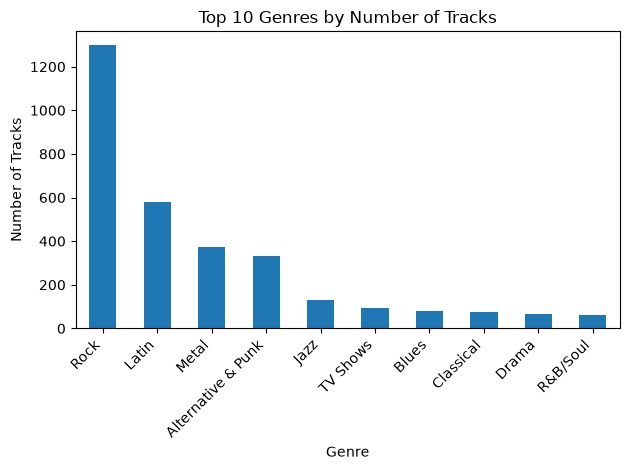

In [10]:
genre_counts.head(10).plot(kind="bar")
plt.title("Top 10 Genres by Number of Tracks")
plt.xlabel("Genre")
plt.ylabel("Number of Tracks")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

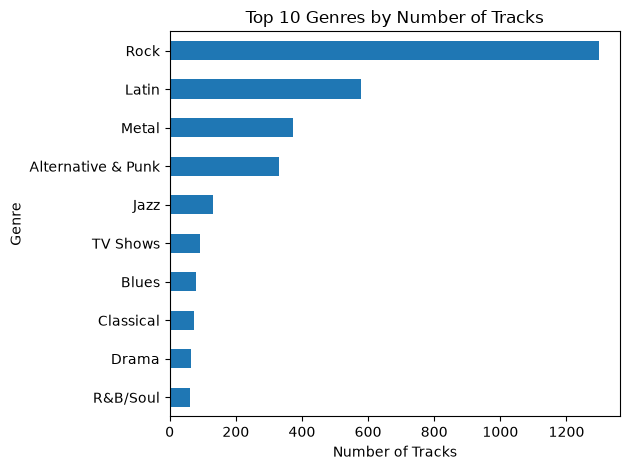

In [11]:
genre_counts.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Genres by Number of Tracks")
plt.ylabel("Genre")
plt.xlabel("Number of Tracks")
plt.tight_layout()
plt.show()

In [12]:
df["Minutes"] = df["Milliseconds"] / 60000
print(df["Minutes"].describe())

count    3503.000000
mean        6.559987
std         8.916757
min         0.017850
25%         3.454683
50%         4.260567
75%         5.360750
max        88.115883
Name: Minutes, dtype: float64


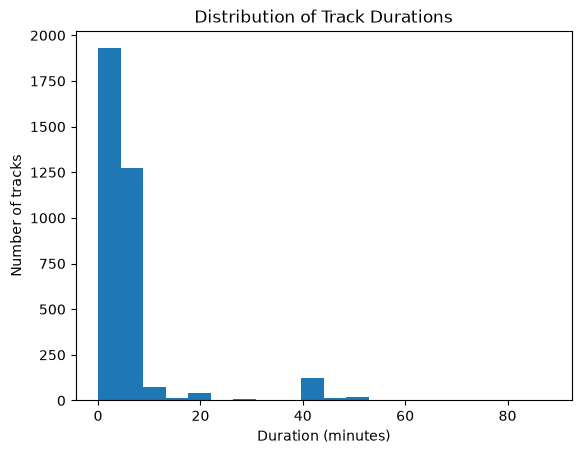

In [21]:
plt.hist(df["Minutes"], bins=20)
plt.title("Distribution of Track Durations")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of tracks")
plt.show()

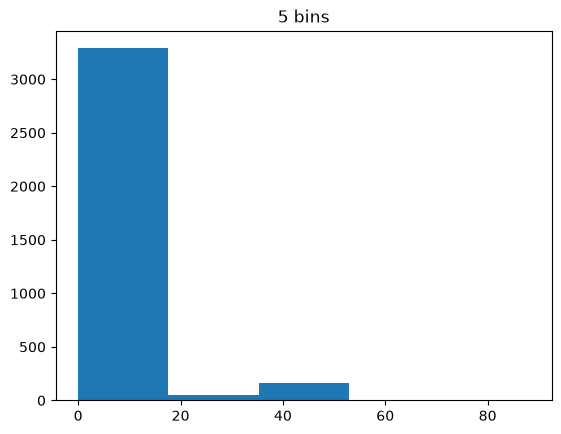

In [22]:
plt.hist(df["Minutes"], bins=5)
plt.title("5 bins")
plt.show()



<class 'pandas.DataFrame'>
Index: 3285 entries, 0 to 3502
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   song          3285 non-null   str    
 1   genre         3285 non-null   str    
 2   Milliseconds  3285 non-null   int64  
 3   UnitPrice     3285 non-null   float64
 4   Minutes       3285 non-null   float64
dtypes: float64(2), int64(1), str(2)
memory usage: 226.8 KB


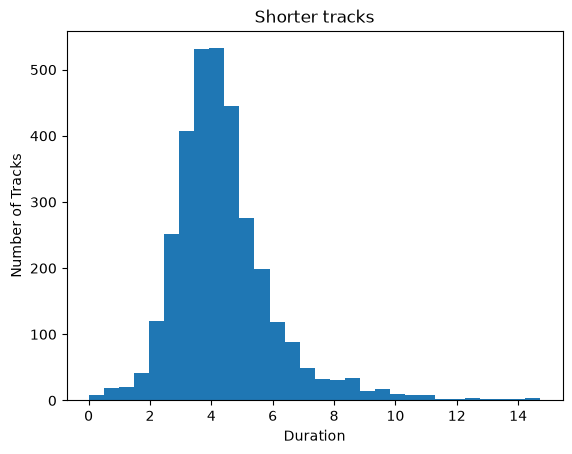

In [29]:

shorter_tracks = df[df["Minutes"] <=15]
plt.hist(shorter_tracks["Minutes"], bins=30)
plt.title("Shorter tracks")
plt.xlabel("Duration")
plt.ylabel("Number of Tracks")

shorter_tracks.info()
df.sort_values("Minutes", ascending=False)[
    ["song", "genre", "Minutes"]
].head(10);

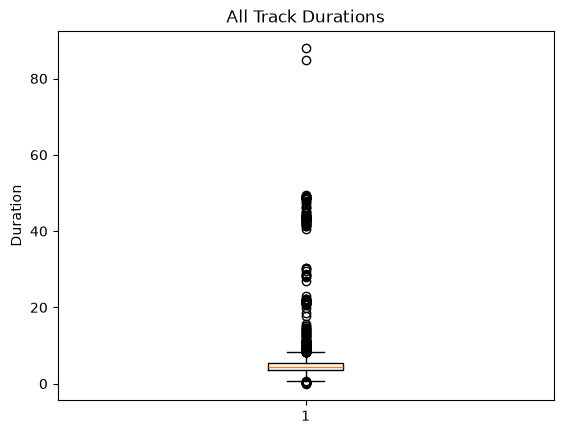

In [30]:
plt.boxplot(df["Minutes"].dropna())
plt.title("All Track Durations")
plt.ylabel("Duration")
plt.show()

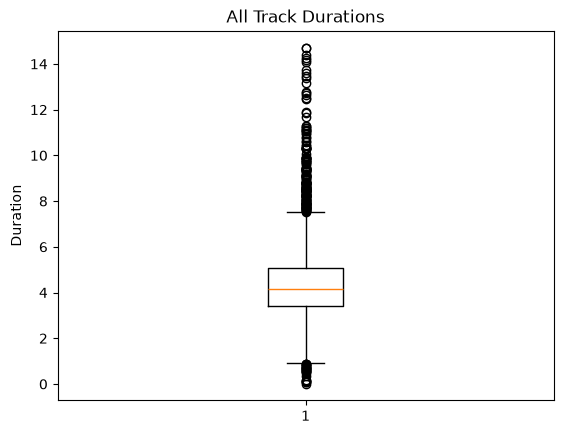

In [31]:
plt.boxplot(shorter_tracks["Minutes"].dropna())
plt.title("All Track Durations")
plt.ylabel("Duration")
plt.show()

### Comparing the filesize of the tracks 

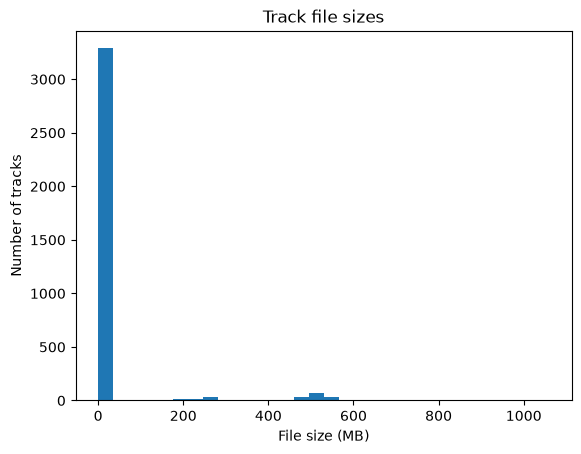

In [33]:
tracks["MB"] = tracks["Bytes"] / 1_000_000
plt.hist(tracks["MB"].dropna(), bins=30)
plt.xlabel("File size (MB)")
plt.ylabel("Number of tracks")
plt.title("Track file sizes")
plt.show()